In [1]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import multiprocessing as mp
import matplotlib.pyplot as plt
from scipy.special import gamma
from stochastic.processes.continuous import FractionalBrownianMotion


def GenerateNoise(H, t_fin, t_init, N, alpha, rng):
    '''
    the parameter rng produces unique series of 
    random numbers at each simulation trajectory
    '''
    fbm = FractionalBrownianMotion(hurst=1-H, t=(t_fin - t_init), rng=rng)
    noise = np.sqrt((2*gamma(3 - alpha) / gamma(1 + alpha))) * fbm.sample(N)
    return noise


def force_term(j, x):
    return x[j-1]


def approxfun(n, alpha, j, x):
    return float(force_term(j,x)*(((n-j+1)**alpha) - ((n-j) ** alpha)))


def simulate_process(args):
    H, t_fin, t_init, N, alpha, A, dt, r, xr, m, w, seed, i = args

    # random number generator with a unique seed
    rng = np.random.default_rng(seed)
    coefficient = (m*(w**2)*(dt**alpha))/(gamma(1+alpha))
    noise = GenerateNoise(H, t_fin, t_init, N, alpha, rng)

    # defining the position array
    x = np.zeros(N)
    xm = 0
    tr = 0
    reset_step = 1
    count = 0
    nn = []

    for n in range(1, N):
        r1 = rng.uniform(0, 1)
        if r1 < r * dt:
            x[n] = xr
            xm = xr
            reset_time = n*dt
            reset_step = n
            noise = GenerateNoise(H, t_fin, t_init+reset_time, N-reset_step, alpha, rng)
            count += 1
        else:
            x[n] = xm + x[0] + (-coefficient*sum(approxfun(n, alpha, j, x) for j in range(reset_step, n+1)) 
                                + noise[n-reset_step])/A

    return x


if __name__ == "__main__":
    r = 1.0         # reset rate 
    xr = 0.0        # reset position 
    m = 1.0         # mass 
    w = 1.0         # barrier frequency 
    zeta = 1.0      # friction coefficient 
    H = 0.6         # Hurst index 
    N = 100000      # simulation steps 
    nreps = 1000    # number of simulations/trajectories 
    t_init = 0.0    # initial time 
    t_fin = 100.0   # final time 
    dt = (t_fin - t_init) / N   # time interval 
    print(f'Time interval = {dt} sec.')
    alpha = 2-2*H
    A = 2*zeta*H*(2*H-1)*gamma(1-alpha)
    t1 = time.time()
    traj = np.zeros((nreps,N), dtype=np.float16) 
    
    with mp.Pool(processes=56) as pool:
        # generate unique seeds for each process
        base_seed = int(time.time())
        seeds = [base_seed + i for i in range(nreps)]
        args = [(H, t_fin, t_init, N, alpha, A, dt, r, xr, m, w, seeds[i], i) for i in range(nreps)]
        trajs = pool.map(simulate_process, args)

    print(f"Simulation time = {(time.time() - t1)/60} min.")

Time interval = 0.001 sec.
Simulation time = 11.736630268891652 min.


In [2]:
df = pd.DataFrame(trajs)
df2 = df.drop(columns=[0])
df2

,1,2,3,4,5,6,7,8,9,10,...,99990,99991,99992,99993,99994,99995,99996,99997,99998,99999
0,0.0,-0.010715,0.113754,0.243428,0.353657,0.351275,0.273847,0.262408,0.263168,0.270925,...,0.680531,0.798096,0.772869,0.837319,0.822032,0.855311,0.956507,1.068821,1.016583,1.104167
1,0.0,0.037562,0.002440,0.006995,0.034854,0.027499,-0.034086,0.036755,0.089195,0.063635,...,-0.142941,-0.163399,-0.287214,-0.328324,-0.465712,-0.436592,-0.298815,-0.485929,-0.387410,-0.250125
2,0.0,0.020742,0.023527,-0.020717,0.006904,-0.010528,0.017946,0.020136,-0.039609,-0.130830,...,0.538337,0.430606,0.576634,0.527180,0.629896,0.666752,0.694899,0.737463,0.669978,0.650670
3,0.0,-0.147777,-0.036948,-0.090721,-0.202192,-0.228249,-0.344189,-0.363814,-0.168463,-0.174877,...,0.297217,0.394006,0.220691,0.175034,0.115063,0.178073,0.224421,0.366638,0.362403,0.376381
4,0.0,-0.034164,-0.001713,-0.007372,0.187563,0.148928,0.212251,0.226735,0.124432,0.169334,...,-0.284388,-0.272011,-0.209857,-0.281324,-0.384902,-0.295671,-0.252721,-0.278670,-0.471572,-0.497128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.0,0.086689,0.084955,0.136932,0.255311,0.081325,0.081583,-0.085995,-0.142284,-0.086694,...,1.447807,1.366891,1.502436,1.404635,1.350543,1.329399,1.448368,1.570030,1.448126,1.386464
996,0.0,-0.030507,0.034622,-0.082514,-0.112448,-0.164121,-0.142365,-0.033211,-0.109278,0.064018,...,0.218728,0.250471,0.355626,0.400809,0.408094,0.189887,0.285339,0.283142,0.476241,0.616980
997,0.0,0.111325,0.095914,0.224043,0.042276,0.044638,0.106992,0.229868,0.338740,0.281366,...,-0.461734,-0.506926,-0.509623,-0.518347,-0.461428,-0.506317,-0.595652,-0.597711,-0.712270,-0.653978
998,0.0,-0.014178,-0.056468,-0.133286,-0.313406,-0.210332,-0.132692,-0.118919,-0.177140,-0.050689,...,-0.003500,-0.084650,0.119030,0.063142,0.016161,0.092882,0.022848,-0.001679,-0.073566,-0.226319


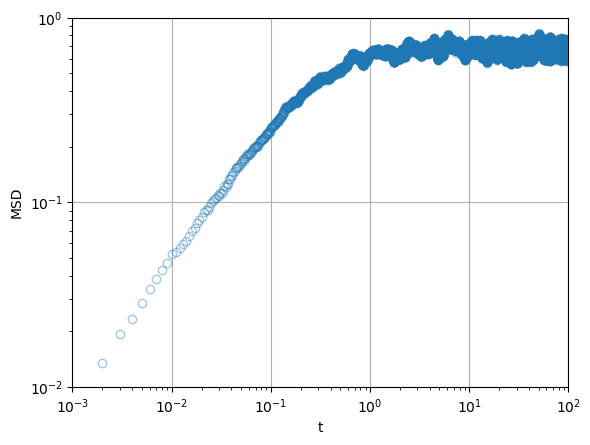

In [22]:
x_r = df2.to_numpy()
disp = x_r - x_r[:, [0]]         
t_init = 0.0
MSD = np.mean(disp**2, axis=0)   # shape (N,)
dt = (t_fin - t_init) / (x_r.shape[1]-1)
T = np.linspace(t_init, t_fin, x_r.shape[1])

plt.figure()
plt.plot(T, MSD, 'o', alpha=0.4, fillstyle='none')
plt.xlabel("t")
plt.ylabel("MSD")
plt.xscale("log")
plt.yscale("log")
plt.xlim(0.001,100)
plt.ylim(0.01,1)
plt.grid(True)
plt.show()

In [12]:
df_th = pd.read_csv("./msd/rev-1/msd_under_resetting_with_trap_H0.6_diff_r.csv")
df_th

,time,r = 0,r = 0.1,r = 1,r = 10
0,0.000010,0.000195,0.000195,0.000195,0.000195
1,0.000013,0.000234,0.000234,0.000234,0.000234
2,0.000016,0.000282,0.000282,0.000282,0.000282
3,0.000020,0.000339,0.000339,0.000339,0.000339
4,0.000025,0.000407,0.000407,0.000407,0.000407
...,...,...,...,...,...
86,3981.071706,1.000000,0.943828,0.671726,0.227595
87,5011.872336,1.000000,0.943828,0.671726,0.227595
88,6309.573445,1.000000,0.943828,0.671726,0.227595
89,7943.282347,1.000000,0.943828,0.671726,0.227595


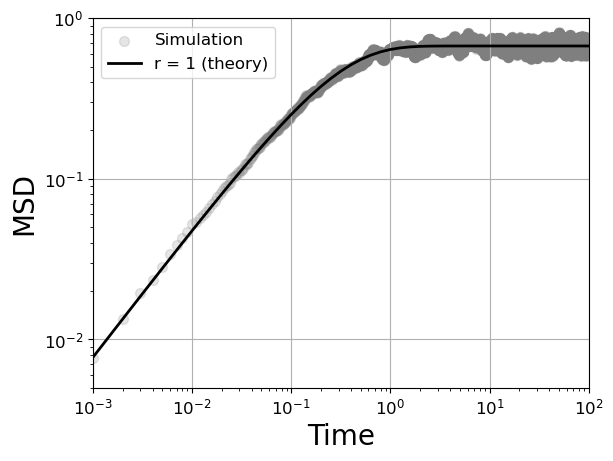

In [18]:
plt.scatter(T, MSD, alpha=0.2, s=50, color="tab:grey", label="Simulation")
# plt.plot(df_th['time'], df_th['r = 0'], color='tab:blue', linewidth=2, label="r = 0")
plt.plot(df_th['time'], df_th['r = 1'], color='black', linewidth=2, label="r = 1 (theory)")
# plt.plot(df_th['time'], df_th['r = 10'], color='tab:green', linewidth=2, label="r = 10")

plt.xscale("log")
plt.yscale("log")
plt.xlim(0.001,100)
plt.ylim(0.005,1)
plt.xlabel("Time", fontsize=20)
plt.ylabel("MSD", fontsize=20)
plt.tick_params(axis="both", labelsize=12)
plt.legend(fontsize=12)
plt.grid()
plt.show()

In [19]:
df3 = pd.DataFrame(T, MSD)
df3

,0
0.000000,0.000
0.007617,0.001
0.013426,0.002
0.019481,0.003
0.023510,0.004
...,...
0.676891,99.996
0.675878,99.997
0.678452,99.998
0.676111,99.999


In [21]:
# df3.to_csv("/home/debasish/escape_under_resetting/msd/rev-1/simulation/fig_3D_diff_H/msd_H0.75.csv")